# Feature Engineering - Used Car Price Prediction

Mục tiêu của notebook:
1. Tạo đặc trưng mới từ văn bản (cờ 'chính chủ', cờ 'zin') và chỉ số sử dụng xe (`km_per_year`).
2. Xử lý các biến phân loại bằng One-Hot Encoding (gom nhóm danh mục hiếm cho hãng xe và tỉnh thành).
3. Chuẩn hóa đặc trưng số (Scaling) bằng `StandardScaler`.
4. Phân chia Train/Test độc lập chống rò rỉ dữ liệu (Data Leakage) và xuất dữ liệu sẵn sàng cho giai đoạn Modeling.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sys.path.append(os.path.abspath('.'))
from feature_builder import build_features
from preprocessor import (
    group_low_frequency_categories,
    group_top_n_categories,
    build_column_transformer,
    fit_transform_features,
    save_artifacts
)

%matplotlib inline

In [2]:
# Nạp dữ liệu đã làm sạch
data_path = '../Data/data_cleaning/cars_cleaned.csv' if os.path.exists('../Data/data_cleaning/cars_cleaned.csv') else 'Data/data_cleaning/cars_cleaned.csv'
df = pd.read_csv(data_path)
print(f"Dữ liệu ban đầu: {df.shape[0]} dòng, {df.shape[1]} cột")
df.head(3)

Dữ liệu ban đầu: 12494 dòng, 21 cột


,list_id,subject,price_million,mfdate,car_age,odo_km,carbrand_name,carmodel_name,region_name,region_name_v3,...,ward_name,list_time,flag_chinh_chu,flag_bao_duong_hang,gearbox,fuel,cartype,carcolor,carorigin,carseats
0,94613937,ISUZU DMAX NHẬP THÁI SỐ TỰ ĐỘNG SIÊU KENG RẤT ĐẸP,475.0,2014,12,80000.0,Isuzu,Dmax,An Giang,An Giang,...,Thị trấn Mỹ Luông,1786860877000,0,0,Số tự động,Dầu,Bán tải,Unknown,Nhập khẩu Thái Lan,Unknown
1,101546338,Ranger XLS AT,615.0,2025,1,22000.0,Ford,Ranger,Hà Nội,TP Hà Nội,...,Phường Hoàng Liệt,1787635662939,0,0,Số tự động,Dầu,Bán tải,Trắng,Lắp ráp trong nước,5 chỗ
2,101725648,terano ll máy dầu 7 chỗ diezen 2 cầu tubo xe đẹp,140.0,2002,24,130000.0,Nissan,Terrano,Hà Nội,TP Hà Nội,...,Phường Phúc La,1785372154000,0,0,Số sàn,Dầu,SUV / Crossover,Unknown,Nhập khẩu Nhật Bản,7 chỗ


## 1. Tạo biến mới (Feature Extraction)

- `flag_chinh_chu`: Nhận diện tin đăng xe chính chủ, 1 chủ từ đầu hoặc xe gia đình thông qua phân tích tiêu đề `subject`.
- `flag_zin`: Nhận diện xe giữ được độ nguyên bản cao (máy zin, sơn zin, keo chỉ zin, zin toàn bộ).
- `km_per_year`: Tốc độ tích lũy ODO trung bình mỗi năm (`odo_km / car_age`), phản ánh cường độ vận hành thực tế.

In [3]:
# Tạo các đặc trưng mới từ module feature_builder
df_feat = build_features(df)

print(f"Số lượng xe chính chủ / 1 chủ: {df_feat['flag_chinh_chu'].sum()} ({df_feat['flag_chinh_chu'].mean():.2%})")
print(f"Số lượng xe cam kết 'zin': {df_feat['flag_zin'].sum()} ({df_feat['flag_zin'].mean():.2%})")
print(f"Số lượng xe có lịch sử hãng: {df_feat['flag_bao_duong_hang'].sum()} ({df_feat['flag_bao_duong_hang'].mean():.2%})")

df_feat[['subject', 'flag_chinh_chu', 'flag_zin', 'odo_km', 'car_age', 'km_per_year']].head()

Số lượng xe chính chủ / 1 chủ: 593 (4.75%)


Số lượng xe cam kết 'zin': 191 (1.53%)
Số lượng xe có lịch sử hãng: 109 (0.87%)


,subject,flag_chinh_chu,flag_zin,odo_km,car_age,km_per_year
0,ISUZU DMAX NHẬP THÁI SỐ TỰ ĐỘNG SIÊU KENG RẤT ĐẸP,0,0,80000.0,12,6666.7
1,Ranger XLS AT,0,0,22000.0,1,22000.0
2,terano ll máy dầu 7 chỗ diezen 2 cầu tubo xe đẹp,0,0,130000.0,24,5416.7
3,BMW X6 2010 Full Đồ Chơi Của Hãng,0,0,105000.0,16,6562.5
4,Toyota Fortuner 4x2 2016 một chủ,1,0,120000.0,10,12000.0


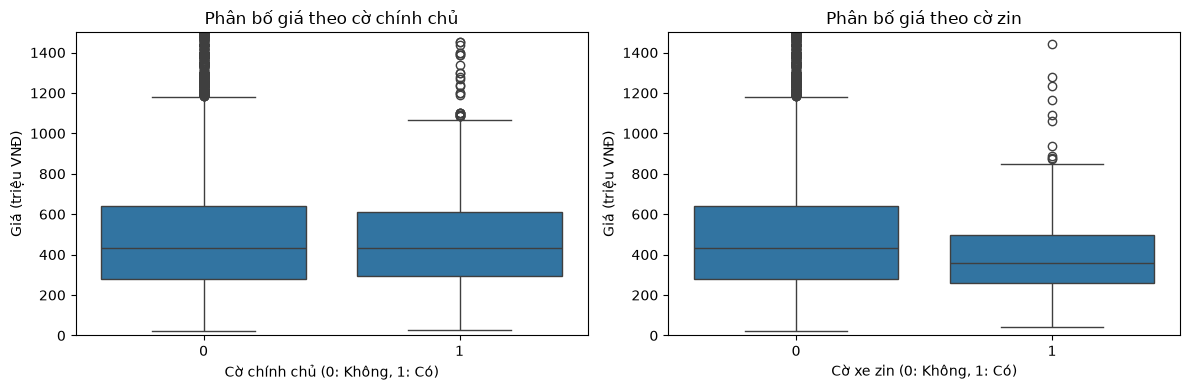

Thống kê giá theo cờ chính chủ:


,count,mean,median
flag_chinh_chu,,,
0,11901,517.630299,435.0
1,593,490.507036,435.0



Thống kê giá theo cờ zin:


,count,mean,median
flag_zin,,,
0,12303,517.876815,435.0
1,191,417.541361,359.0


In [4]:
# Phân tích tương quan giá theo cờ chính chủ và cờ zin
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df_feat, x='flag_chinh_chu', y='price_million', ax=axes[0])
axes[0].set_title('Phân bố giá theo cờ chính chủ')
axes[0].set_ylim(0, 1500)
axes[0].set_xlabel('Cờ chính chủ (0: Không, 1: Có)')
axes[0].set_ylabel('Giá (triệu VNĐ)')

sns.boxplot(data=df_feat, x='flag_zin', y='price_million', ax=axes[1])
axes[1].set_title('Phân bố giá theo cờ zin')
axes[1].set_ylim(0, 1500)
axes[1].set_xlabel('Cờ xe zin (0: Không, 1: Có)')
axes[1].set_ylabel('Giá (triệu VNĐ)')

plt.tight_layout()
plt.show()

print("Thống kê giá theo cờ chính chủ:")
display(df_feat.groupby('flag_chinh_chu')['price_million'].agg(['count', 'mean', 'median']))

print("\nThống kê giá theo cờ zin:")
display(df_feat.groupby('flag_zin')['price_million'].agg(['count', 'mean', 'median']))

## 2. Xử lý biến phân loại và gom nhóm danh mục hiếm

- Biến `carbrand_name` có 55 hãng xe. Các hãng có dưới 50 tin đăng được gom vào nhóm `'Khác'` nhằm tránh bùng nổ số chiều khi One-Hot Encoding.
- Biến `region_name` có 63 tỉnh thành. Giữ lại top 10 tỉnh thành giao dịch sôi động nhất và gom các tỉnh còn lại vào nhóm `'Khác'`.

In [5]:
# Gom nhóm danh mục có tần suất thấp
df_feat['carbrand_grouped'] = group_low_frequency_categories(df_feat['carbrand_name'], min_count=50, other_label='Khác')
df_feat['region_grouped'] = group_top_n_categories(df_feat['region_name'], top_n=10, other_label='Khác')

print(f"Số hãng xe sau khi gom nhóm: {df_feat['carbrand_grouped'].nunique()} (ban đầu: {df_feat['carbrand_name'].nunique()})")
print(f"Số tỉnh thành sau khi gom nhóm: {df_feat['region_grouped'].nunique()} (ban đầu: {df_feat['region_name'].nunique()})")

Số hãng xe sau khi gom nhóm: 23 (ban đầu: 55)
Số tỉnh thành sau khi gom nhóm: 11 (ban đầu: 63)


## 3. Phân chia tập Train / Test

- Tách riêng tập Train (80%) và tập Test (20%) trước khi Encoding và Scaling.
- Bộ chuyển đổi chỉ được `fit` trên tập Train để ngăn ngừa rò rỉ thông tin từ tập Test (Data Leakage).

In [6]:
cat_cols = ['carbrand_grouped', 'region_grouped', 'gearbox', 'fuel', 'cartype', 'carorigin']
num_cols = ['car_age', 'odo_km', 'km_per_year']
bin_cols = ['flag_chinh_chu', 'flag_zin', 'flag_bao_duong_hang']

features = cat_cols + num_cols + bin_cols
target = 'price_million'

X = df_feat[features]
y = df_feat[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Kích thước tập Train: {X_train.shape[0]} dòng, {X_train.shape[1]} đặc trưng gốc")
print(f"Kích thước tập Test: {X_test.shape[0]} dòng, {X_test.shape[1]} đặc trưng gốc")

Kích thước tập Train: 9995 dòng, 12 đặc trưng gốc
Kích thước tập Test: 2499 dòng, 12 đặc trưng gốc


## 4. One-Hot Encoding và Scaling

- `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`: Biến đổi các cột phân loại thành ma trận 0/1.
- `StandardScaler()`: Chuẩn hóa các cột số liên tục về giá trị có kỳ vọng 0 và phương sai 1.
- `passthrough`: Giữ nguyên các biến cờ nhị phân (0 hoặc 1).

In [7]:
# Xây dựng ColumnTransformer và biến đổi dữ liệu
preprocessor = build_column_transformer(
    categorical_cols=cat_cols,
    numerical_cols=num_cols,
    binary_cols=bin_cols,
    scaler_type='standard'
)

X_train_df, X_test_df, fitted_preprocessor = fit_transform_features(
    X_train=X_train,
    X_test=X_test,
    preprocessor=preprocessor
)

print(f"Số lượng đặc trưng sau biến đổi: {X_train_df.shape[1]}")
print("Kích thước X_train sau biến đổi:", X_train_df.shape)
print("Kích thước X_test sau biến đổi:", X_test_df.shape)

Số lượng đặc trưng sau biến đổi: 68
Kích thước X_train sau biến đổi: (9995, 68)
Kích thước X_test sau biến đổi: (2499, 68)


In [8]:
# Xem trước dữ liệu sau xử lý
print("10 cột đặc trưng đầu tiên:")
print(list(X_train_df.columns[:10]))

print("\nCác cột đặc trưng số và cờ nhị phân:")
print(list(X_train_df.columns[-6:]))

X_train_df.head(3)

10 cột đặc trưng đầu tiên:
['carbrand_grouped_Audi', 'carbrand_grouped_BMW', 'carbrand_grouped_Chevrolet', 'carbrand_grouped_Daewoo', 'carbrand_grouped_Ford', 'carbrand_grouped_Hãng khác', 'carbrand_grouped_Honda', 'carbrand_grouped_Hyundai', 'carbrand_grouped_Isuzu', 'carbrand_grouped_Khác']

Các cột đặc trưng số và cờ nhị phân:
['car_age', 'odo_km', 'km_per_year', 'flag_chinh_chu', 'flag_zin', 'flag_bao_duong_hang']


,carbrand_grouped_Audi,carbrand_grouped_BMW,carbrand_grouped_Chevrolet,carbrand_grouped_Daewoo,carbrand_grouped_Ford,carbrand_grouped_Hãng khác,carbrand_grouped_Honda,carbrand_grouped_Hyundai,carbrand_grouped_Isuzu,carbrand_grouped_Khác,...,carorigin_Nhập khẩu Đài Loan,carorigin_Nhập khẩu Đức,carorigin_Nhập khẩu Ấn Độ,carorigin_Unknown,car_age,odo_km,km_per_year,flag_chinh_chu,flag_zin,flag_bao_duong_hang
5466,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-0.961912,-0.428183,1.897254,0.0,0.0,0.0
9965,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-0.126510,1.269744,1.308117,0.0,0.0,0.0
9118,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-0.627751,0.105451,1.199360,0.0,0.0,0.0


In [9]:
# Kiểm tra phân bố các biến số sau chuẩn hóa
display(X_train_df[num_cols].describe().round(2))

,car_age,odo_km,km_per_year
count,9995.00,9995.00,9995.00
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.30,-1.32,-1.59
25%,-0.79,-0.70,-0.64
50%,-0.29,-0.16,-0.23
75%,0.37,0.38,0.41
max,6.39,6.77,4.75


## 5. Xuất kết quả tiền xử lý (Export Artifacts)

- Lưu trữ các tập dữ liệu `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`.
- Lưu pipeline tiền xử lý `preprocessor.joblib` để sử dụng trực tiếp khi huấn luyện và dự đoán mô hình.

In [10]:
output_dir = 'data_processed'
save_artifacts(
    X_train=X_train_df,
    X_test=X_test_df,
    y_train=y_train,
    y_test=y_test,
    preprocessor=fitted_preprocessor,
    output_dir=output_dir
)
print(f"Đã lưu artifacts thành công vào: {output_dir}")
print("Danh sách file đã lưu:", os.listdir(output_dir))

Đã lưu artifacts thành công vào: data_processed
Danh sách file đã lưu: ['preprocessor.joblib', 'X_test.csv', 'X_train.csv', 'y_test.csv', 'y_train.csv']
